# Econ 4850 · Economic Analysis with Python
## Lecture 3a: NumPy
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- How to create NumPy arrays and why preallocating them matters for speed.
- How to evaluate a function over an entire grid of states without `for` loops, using vectorization, `np.meshgrid` and broadcasting.
- How to impose constraints with `np.where`, and how to slice and index arrays.
- How to compute the OLS estimator with NumPy's linear algebra.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

## Introduction to Scientific Computing: NumPy

- We did some scientific computing in Homework 1. However, that is not how we typically write code for economic problems.

- Instead, we typically use [NumPy](https://numpy.org/doc/stable/index.html), short for Numerical Python.

- Many common Python libraries are built on top of NumPy.

- Loosely speaking, a NumPy array is a more efficient and more sophisticated version of a list `[]`.
    - The efficiency comes mainly from storing data in a contiguous block of memory and from precompiled C and C++ implementations under the hood.

### What does NumPy provide?

1. An n-dimensional array object (`ndarray`).

2. Fast, vectorized array operations.

3. Sophisticated broadcasting.

4. A large collection of mathematical functions for element-wise computation, linear algebra, Fourier transforms, and more.

### Why do we need NumPy?

1. **Performance**
    - NumPy arrays are optimized for speed. Many operations are implemented in C/C++ and run much faster than pure Python on large datasets. This is crucial for time-sensitive tasks such as financial modeling, statistical analysis, and simulation.

2. **Foundation for other libraries**
    - NumPy provides the underlying data structure for popular libraries in the PyData stack, such as SciPy and pandas.

3. **Vectorized operations**
    - Vectorization lets you apply an operation to an entire array instead of looping over individual elements in pure Python. This leads to cleaner, more readable code that is typically faster.

4. **Broadcasting**
    - NumPy's broadcasting mechanism handles arrays of different shapes in arithmetic operations. This lets you perform complex manipulations of data with minimal, expressive code.

We will see each of these throughout the lecture.

## Using NumPy

- Anaconda includes NumPy, so we can `import` it directly.

- Since we use NumPy everywhere, we save typing with `import numpy as np`.

### Creating arrays

- Usually, we first create an array to store the results of our computation.

- Ideally, create an array whose shape you will never need to change.
    - Loosely speaking: always allocate the memory before the computation.

- NumPy offers several ways to create arrays.

In [2]:
x = np.array([1, 2, 3, 4, 5])
print(f'x = {x}')

# Array of zeros
y = np.zeros(5)
print(f'y = {y}')

# Array of ones
shape = (3, 2)
z = np.ones(shape)
print(f'z = {z}')

# 2D array of uniform random numbers
w = np.random.rand(*shape)
print(f'w = {w}')

# Evenly spaced points
u = np.linspace(0, 10, 5)
print(f'u = {u}')

x = [1 2 3 4 5]
y = [0. 0. 0. 0. 0.]
z = [[1. 1.]
 [1. 1.]
 [1. 1.]]
w = [[0.73978281 0.31594191]
 [0.34781919 0.8815187 ]
 [0.18579471 0.47203919]]
u = [ 0.   2.5  5.   7.5 10. ]


- I want to highlight `np.linspace(...)`. In economics, decisions are functions of states (e.g., income, wealth, age). We usually create a grid over all possible states, because we want the solution to be right at every state.

- When the state space is multi-dimensional, broadcasting makes creating grids of states extremely easy.
    - We will return to this later.
    - In other words, you no longer need to "vectorize" your state space by hand.

In [3]:
# Grid of working ages
grid_age = np.linspace(25, 66, 42)
print(grid_age)

[25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36. 37. 38. 39. 40. 41. 42.
 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53. 54. 55. 56. 57. 58. 59. 60.
 61. 62. 63. 64. 65. 66.]


### Memory efficiency

- A NumPy array is much more memory efficient than a list.

- A Python list stores pointers to objects, which adds significant overhead.

- Hence, the memory used by a list includes both the list itself and its elements.

In [4]:
for n in range(1, 8, 2):
    large_list = [i for i in range(10**n)]
    large_array = np.arange(10**n)
    list_bytes = sys.getsizeof(large_list) + sum(sys.getsizeof(item) for item in large_list)
    print(f"When n = {n},")
    print("the NumPy array is", list_bytes / large_array.nbytes,
          "times smaller than the Python list.\n")

When n = 1,
the NumPy array is 5.8 times smaller than the Python list.

When n = 3,
the NumPy array is 4.607 times smaller than the Python list.

When n = 5,
the NumPy array is 4.50123 times smaller than the Python list.



When n = 7,
the NumPy array is 4.6136895 times smaller than the Python list.



### Trick 1: use `np.empty` when every entry will be overwritten

- If you will eventually replace all the data in an array, create it with `np.empty`.

- Let's see how large the time difference can be.

In [5]:
%%timeit
# Time the creation of arrays with np.empty
size = int(1e4)
for i in range(size):
    v = np.empty(size)

1.65 ms ± 250 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [6]:
%%timeit
# Same loop with np.zeros
size = int(1e4)
for i in range(size):
    v = np.zeros(size)

12.9 ms ± 702 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


- `np.empty(...)` does not fill the array, so its entries are whatever happened to be in memory. That is why you should use it only when you will overwrite every entry.

In [7]:
# What is inside an empty array?
print(np.empty(10))

[0.0e+000 4.9e-324 9.9e-324 1.5e-323 2.0e-323 2.5e-323 3.0e-323 3.5e-323
 4.0e-323 4.4e-323]


- Because `np.empty(...)` skips the fill step, it is created significantly faster.

### Trick 2: create the full-size array instead of appending

- Whenever possible, create the full-size array up front instead of using `np.append`.

In [8]:
v = np.array([0])
np.append(v, 10)

array([ 0, 10])

In [9]:
%%timeit
N = 10_000
v = np.array([0])
for i in range(1, N):
    v = np.append(v, i)

25.6 ms ± 923 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [10]:
%%timeit
N = 10_000
v = np.empty(N)
for i in range(N):
    v[i] = i

499 μs ± 19.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## Array Operations

- NumPy array operations are element-wise.

In [11]:
x = np.arange(10)
print(x)
print(x + 1)
print(x * 2)
print(1 / x)  # 1/0 gives inf (with a warning)
print(x * x)  # element-wise product
print(np.dot(x, x))  # inner product

[0 1 2 3 4 5 6 7 8 9]
[ 1  2  3  4  5  6  7  8  9 10]
[ 0  2  4  6  8 10 12 14 16 18]
[       inf 1.         0.5        0.33333333 0.25       0.2
 0.16666667 0.14285714 0.125      0.11111111]
[ 0  1  4  9 16 25 36 49 64 81]
285


<ipython-input>:5: RuntimeWarning: divide by zero encountered in divide
  print(1 / x)  # 1/0 gives inf (with a warning)


- NumPy has many built-in operations. Use them whenever possible, as they are more efficient.

- You don't have to memorize them, but you should at least have a [look](https://numpy.org/doc/2.1/reference/routines.math.html).

### Evaluating a function across the state space

- In economics, we often want to evaluate a function at every possible state.

- For example, we may want to know how much people consume at every possible income level.

- NumPy makes this computation efficient.

[  1.           5.99813664  10.00914591  13.71631247  17.23899385
  20.63055726  23.921165    27.13012327  30.27080143  33.35297764
  36.38409763  39.37000952  42.31542112  45.22419884  48.09957138
  50.94427288  53.76064666  56.55072198  59.31627214  62.05885914
  64.77986871  67.48053796  70.16197767  72.82519028  75.47108479
  78.1004889   80.71415933  83.31279033  85.89702099  88.46744142
  91.02459808  93.56899833  96.10111443  98.62138693 101.13022777
 103.62802287 106.11513448 108.59190325 111.05865009 113.51567776
 115.96327236 118.40170465 120.83123119 123.25209545 125.66452873
 128.06875106 130.46497194 132.85339112 135.23419923 137.60757835
 139.97370258 142.33273858 144.68484595 147.03017773 149.36888073
 151.70109595 154.02695888 156.3465998  158.66014409 160.96771249
 163.26942133 165.56538281 167.85570514 170.14049282 172.41984674
 174.69386446 176.96264027 179.22626541 181.48482821 183.73841417
 185.98710618 188.23098454 190.47012715 192.70460958 194.93450516
 197.15988

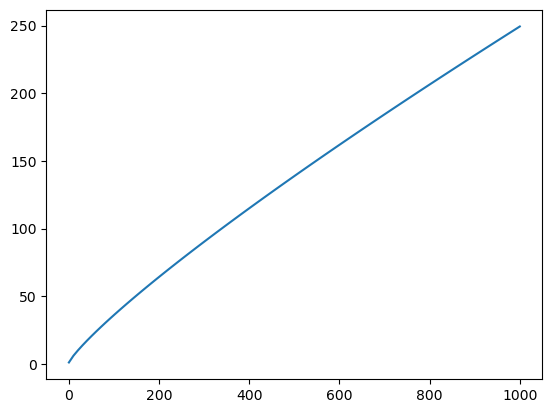

In [12]:
def consumption(y):
    return 0.7 * y**0.85 + 1


min_y = 0
max_y = 1000

size_of_array = 100
y = np.linspace(min_y, max_y, size_of_array)

plt.plot(y, consumption(y))
print(consumption(y))

- More importantly, this element-wise operation applies to the whole vector (array) at once.

- We can therefore avoid a `for` loop over states and make our code faster.

### Horse race: list vs. preallocated array vs. vectorization

First, a naive `for` loop that appends to a list.

In [13]:
%%timeit
c_list = []
for i in range(len(y)):
    c_list.append(consumption(y[i]))

17 μs ± 464 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


Next, a loop that fills a preallocated NumPy array, which is cleaner.

In [14]:
%%timeit
c_array = np.zeros(size_of_array)
for iy, vy in enumerate(y):
    # Store consumption at income vy in position iy
    c_array[iy] = consumption(vy)

17.5 μs ± 368 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


But, as we have already seen, we can avoid the `for` loop entirely.

In [15]:
%%timeit
c_array = consumption(y)

2.69 μs ± 8.76 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


### Multi-dimensional state space

- In economics, states can be multi-dimensional.

- An obvious approach is to vectorize the state space yourself. However, this can be tedious and it costs memory.

- Learning to vectorize the state space used to be a must for computing many economic models, but many packages now do it automatically. We will return to this later.

- `np.meshgrid` defaults to Cartesian indexing (`indexing='xy'`), which swaps the roles of the first two inputs. Matrix indexing (`indexing='ij'`) keeps the axes in the order of the inputs, which is what broadcasting assumes. Note also that NumPy stores arrays in row-major (C) order, whereas Fortran and MATLAB, in which much economics code is written, store them in column-major order.

- Be careful when you reshape your arrays!

### Why do we care?

- We eliminated one `for` loop above when the state space was one-dimensional.

- It is slightly more complicated to do this in a multi-dimensional space.

- Let's compute a Cobb–Douglas production function at every possible state.

In [16]:
def cobb_douglas(k, labor, alpha=0.5):
    return np.power(k, alpha) * np.power(labor, 1 - alpha)

Passing the two grids directly does not work: arrays of shapes `(200,)` and `(5,)` cannot be combined element-wise, so the next cell raises a `ValueError` on purpose.

In [17]:
k_grid = np.linspace(0, 100, 200)
l_grid = np.linspace(0, 5, 5)

cobb_douglas(k_grid, l_grid)  # expected error: shapes do not match

ValueError: operands could not be broadcast together with shapes (200,) (5,) 

A double loop works:

In [18]:
%%timeit
production = np.zeros((len(k_grid), len(l_grid)))
for ik, vk in enumerate(k_grid):
    for il, vl in enumerate(l_grid):
        production[ik, il] = cobb_douglas(vk, vl)

1.18 ms ± 5.93 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


We can avoid one `for` loop.

In [19]:
%%timeit
production = np.zeros((len(k_grid), len(l_grid)))
for il, vl in enumerate(l_grid):
    # ":" selects the whole axis
    production[:, il] = cobb_douglas(k_grid, vl)

19.7 μs ± 224 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


But what if the state space has even more dimensions? Is there a general way to vectorize, regardless of the number of dimensions?

### Introduction to vectorizing your state space

In [20]:
# Learning np.meshgrid
x = np.arange(1, 6, 2)
y = np.arange(0, 5, 2)

print(x)
print(y)
print('the shape is', np.shape(x))
print('-' * 10)

# Cartesian indexing ('xy', the default)
X, Y = np.meshgrid(x, y, indexing='xy')
print(X)
print('the shape is', np.shape(X))
print(Y)

print('-' * 16)

# Matrix indexing ('ij')
X, Y = np.meshgrid(x, y, indexing='ij')
print(X)
print('the first row', X[0])
print('the second row', X[1])
print(Y)
print('the first row', Y[0])
print('the second row', Y[1])

[1 3 5]
[0 2 4]
the shape is (3,)
----------
[[1 3 5]
 [1 3 5]
 [1 3 5]]
the shape is (3, 3)
[[0 0 0]
 [2 2 2]
 [4 4 4]]
----------------
[[1 1 1]
 [3 3 3]
 [5 5 5]]
the first row [1 1 1]
the second row [3 3 3]
[[0 2 4]
 [0 2 4]
 [0 2 4]]
the first row [0 2 4]
the second row [0 2 4]


In [21]:
def utility(y, w, labor, alpha=0.5):
    return np.power(y, alpha) * np.power(w, 1 - alpha) - labor * 10

In [22]:
y = np.linspace(0, 100, 100)  # income
w = np.linspace(0, 1000, 1000)  # wealth
labor = np.linspace(0, 1, 5)  # labor

y_mesh, w_mesh, labor_mesh = np.meshgrid(y, w, labor, indexing='ij')
print(np.shape(y_mesh))
print(np.shape(w_mesh))
print(np.shape(labor_mesh))

(100, 1000, 5)
(100, 1000, 5)
(100, 1000, 5)


In [23]:
u_mesh = utility(y_mesh, w_mesh, labor_mesh)
# Equivalent one-liner: unpack the meshgrid directly into the function
u_mesh_alt = utility(*np.meshgrid(y, w, labor, indexing="ij"))
np.array_equal(u_mesh, u_mesh_alt)

True

Check the result against a triple loop:

In [24]:
u_loop = np.zeros((100, 1000, 5))
for il, vl in enumerate(labor):
    for iw, vw in enumerate(w):
        for iy, vy in enumerate(y):
            u_loop[iy, iw, il] = utility(vy, vw, vl)

In [25]:
np.allclose(u_mesh, u_loop)

True

### Trick 3: broadcasting

- With NumPy, you don't even need `np.meshgrid`.

- Even though vectorization is convenient, building the full state space costs memory.

- If you compute on a GPU, running out of memory is fatal.

- Instead, reshape each grid so that it lies along its own axis, and let broadcasting do the rest.

In [26]:
print(np.shape(y))
ys = y.reshape(-1, 1, 1)  # -1 means "infer this dimension from the data"
print(np.shape(ys))
ws = w.reshape(1, -1, 1)
ls = labor.reshape(1, 1, -1)

# Alternative: indexing with None adds new axes
y[:, None, None].shape

(100,)
(100, 1, 1)


(100, 1, 1)

In [27]:
np.array_equal(utility(ys, ws, ls), u_mesh)

True

### Conditioning with `np.where` for constraints

- `np.where` lets you apply an `if` in a vectorized fashion.

In [28]:
def log_u(x):
    if x > 0:
        return np.log(x)
    else:
        return -np.inf

In [29]:
x = np.linspace(-2, 2, 10)
print(x)
log_u_loop = np.empty(x.size)

for i, v in enumerate(x):
    log_u_loop[i] = log_u(v)

[-2.         -1.55555556 -1.11111111 -0.66666667 -0.22222222  0.22222222
  0.66666667  1.11111111  1.55555556  2.        ]


A `for` loop is not worth it for this `if` statement. Note that `np.where` evaluates `np.log(x)` at every point, so NumPy warns about the negative entries even though those values are discarded.

In [30]:
def log_u_vec(x):
    return np.where(x > 0, np.log(x), -np.inf)

In [31]:
log_u_vec(x)

<ipython-input>:2: RuntimeWarning: invalid value encountered in log
  return np.where(x > 0, np.log(x), -np.inf)


array([       -inf,        -inf,        -inf,        -inf,        -inf,
       -1.5040774 , -0.40546511,  0.10536052,  0.44183275,  0.69314718])

### Practice

- Suppose that for unconstrained households $$c=\max\{0.7y+0.1w+10,\ 0.2w\}.$$

- However, there is a zero-borrowing constraint, so consumption cannot exceed $y+w$.

- Write this function using `np.where`, and find consumption at every possible $(y,w)$.

- `np.where` is useful because it applies an `if` to a whole array, which is how we represent a constraint. When we use JAX later, you will see that in many cases we cannot use `if` at all.

- Hint: you should apply `np.where` twice. How can you ensure that the order of the two `np.where` calls does not affect the solution?

In [32]:
y_min = 0
y_max = 100
n_y = 100

w_min = 0
w_max = 1000
n_w = 10000

y = np.linspace(y_min, y_max, n_y)
y = y.reshape(-1, 1)
w = np.linspace(w_min, w_max, n_w)
w = w.reshape(1, -1)


def consumption_constrained(y, w):
    # c0 is the first argument of the max (unconstrained consumption)
    c0 = 0.7 * y + 0.1 * w + 10
    # c_alt is the second argument of the max
    c_alt = 0.2 * w
    # c1 = max(c0, c_alt)
    c1 = np.where(c_alt > c0, c_alt, c0)
    # Impose the borrowing constraint c <= y + w
    c2 = np.where(y + w < c1, y + w, c1)
    return c2

In [33]:
consumption_constrained(y, w).shape

(100, 10000)

## Slicing and Indexing

- We did some indexing in the last lecture, so we will go over this section quickly.

In [34]:
# Basic indexing
# Create a 1D array
arr = np.array([10, 20, 30, 40, 50])

# Access elements
print(arr[0])  # Output: 10
print(arr[3])  # Output: 40

10
40


In [35]:
# Negative indexing
print(arr[-1])  # Output: 50 (last element)
print(arr[-2])  # Output: 40 (second-to-last element)

50
40


In [36]:
# Multidimensional array
# Create a 2D array
arr2d = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])

# Access elements
print(arr2d[0, 2])  # Output: 3 (first row, third column)
print(arr2d[:, 1])  # Output: [2 5 8] (all rows, second column)
print(arr2d[:, 1].shape)  # integer index drops the axis
print(arr2d[:, 1:2].shape)  # slice keeps the axis

3
[2 5 8]
(3,)
(3, 1)


In [37]:
# Slicing a 1D array
print(arr[1:4])  # Output: [20 30 40]
print(arr[:3])  # Output: [10 20 30]
print(arr[::2])  # Output: [10 30 50] (step = 2)

# Slicing a 2D array
print(arr2d[1:, :2])  # Output: [[4 5] [7 8]]
                      # (rows 1 to end, columns 0 to 1)

[20 30 40]
[10 20 30]
[10 30 50]
[[4 5]
 [7 8]]


In [38]:
# Advanced indexing
# Boolean indexing
positions = np.arange(arr.size)
print(arr[positions % 2 == 0])  # Output: [10 30 50]

# List indexing
print(arr[[0, 2, 4]])  # Output: [10 30 50]

[10 30 50]
[10 30 50]


- Boolean indexing is quite useful. A common application is writing the likelihood function for maximum likelihood estimation (MLE).

- Finally, `.copy()` creates an independent array: changing the copy `b` below leaves the original `a` unchanged.

In [39]:
n = 10
a = np.arange(n)
b = a.copy()
b[0] = 100

In [40]:
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

## Linear Algebra with OLS

- Recall that OLS has a closed-form solution for the coefficients, $$\boldsymbol{\beta}=(\mathbf{X}'\mathbf{X})^{-1}\mathbf{X}'\mathbf{y},$$
where $\mathbf{X}$ is $n\times k$ and $\mathbf{y}$ is $n\times 1$. Hence, $\boldsymbol{\beta}$ is $k\times 1$.

- Recall the case $k=1$ for intuition.

- Deriving $\boldsymbol{\beta}$ involves matrix calculus.

### Deriving the closed-form solution for the OLS coefficients

The closed-form solution for the OLS coefficients is derived by minimizing the residual sum of squares (equivalently, the mean squared error).

**1. OLS model.** The linear regression model is
$$
y = X\beta + \epsilon,
$$
where:
- $y$ is an $n \times 1$ vector of observed outcomes,
- $X$ is an $n \times k$ matrix of regressors ($n$ observations and $k$ regressors),
- $\beta$ is a $k \times 1$ vector of coefficients to estimate,
- $\epsilon$ is an $n \times 1$ vector of errors.

We estimate $\beta$ by minimizing the residual sum of squares (RSS).

**2. Loss function.** The RSS is
$$
L(\beta) = \|y - X\beta\|^2 = (y - X\beta)^\top (y - X\beta).
$$

**3. Expand the loss function.**
$$
L(\beta) = (y^\top - \beta^\top X^\top)(y - X\beta)
= y^\top y - y^\top X\beta - \beta^\top X^\top y + \beta^\top X^\top X\beta.
$$
Since $\beta^\top X^\top y$ is a scalar, it equals its transpose $y^\top X\beta$, so
$$
L(\beta) = y^\top y - 2y^\top X\beta + \beta^\top X^\top X\beta.
$$

**4. Take the gradient.** To find the minimum, differentiate $L(\beta)$ with respect to $\beta$:
$$
\frac{\partial L(\beta)}{\partial \beta} = -2X^\top y + 2X^\top X\beta.
$$

If you are interested in matrix calculus, see [this very nice introduction](https://www.sciencedirect.com/science/article/pii/S0304407624002070). In practice, it is often enough to remember the shapes of the terms.

**5. Set the gradient to zero.** At the minimum,
$$
-2X^\top y + 2X^\top X\beta = 0
\quad\Longleftrightarrow\quad
X^\top X\beta = X^\top y.
$$

**6. Solve for $\beta$.** Assuming $X^\top X$ is invertible (i.e., $X$ has full column rank: no regressor is an exact linear combination of the others; with an intercept and one regressor, this means the regressor has nonzero variance), the OLS coefficients are
$$
\beta = (X^\top X)^{-1} X^\top y.
$$

Let's implement this in NumPy.

In [41]:
# Simulate data
np.random.seed(850)  # for reproducibility
n_samples = 10000
n_features = 2

# True coefficients: [intercept, slope 1, slope 2]
beta_true = np.array([10, 5, -2])

# Design matrix with a column of ones for the intercept
X = np.random.rand(n_samples, n_features)
X = np.hstack((np.ones((n_samples, 1)), X))

# Generate y with some noise (be careful with the dimensions)
epsilon = np.random.normal(0, 1, n_samples)
y = X @ beta_true + epsilon

# Solve for beta_hat using the OLS formula
X_transpose = X.T
beta_hat = np.linalg.inv(X_transpose @ X) @ (X_transpose @ y)

# Display results
print("True coefficients:", beta_true)
print("Estimated coefficients:", beta_hat)

True coefficients: [10  5 -2]
Estimated coefficients: [10.01172336  4.9776587  -1.99342257]


Let's verify the result with `statsmodels` and `scikit-learn`.

In [42]:
# Verify using statsmodels
model_sm = sm.OLS(y, X).fit()
beta_hat_statsmodels = model_sm.params
print("Statsmodels coefficients:", beta_hat_statsmodels)

# Verify using scikit-learn
model_sklearn = LinearRegression(fit_intercept=False)  # the intercept is already in X
model_sklearn.fit(X, y)
beta_hat_sklearn = model_sklearn.coef_
print("Scikit-learn coefficients:", beta_hat_sklearn)

Statsmodels coefficients: [10.01172336  4.9776587  -1.99342257]
Scikit-learn coefficients: [10.01172336  4.9776587  -1.99342257]


**Question:** Data scientists use OLS and regression, and so do economists. What is the difference?

## Remark: NumPy

- It is impossible to cover every detail of NumPy here.

- What we went through are the features typically used in economics.

- Please skim the NumPy [guide](https://numpy.org/doc/2.1/reference/routines.math.html) to see what else can be done.